# NSL-KDD Preprocessing Pipeline
A clean, modular pipeline for loading, labeling, and preprocessing the NSL-KDD intrusion detection dataset.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn import preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.feature_selection import mutual_info_classif
import warnings

plt.style.use("seaborn-v0_8-whitegrid")


## 1. Configuration

In [3]:
TRAIN_PATH = "./data/KDDTrain+_20Percent.txt"
TEST_PATH  = "./data/KDDTest+.txt"

COLUMNS = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "attack_class", "num_learners",
]

# Columns that are always zero / redundant in NSL-KDD
DROP_COLS = ["num_outbound_cmds", "num_learners"]

CAT_COLS = ["protocol_type", "service", "flag"]

# Unified attack-group mapping (single source of truth)
ATTACK_GROUP = {
    # Probe
    "ipsweep": "Probe", "satan": "Probe", "nmap": "Probe", "portsweep": "Probe",
    "saint": "Probe", "mscan": "Probe",
    # DoS
    "teardrop": "DoS", "pod": "DoS", "land": "DoS", "back": "DoS",
    "neptune": "DoS", "smurf": "DoS", "mailbomb": "DoS", "udpstorm": "DoS",
    "apache2": "DoS", "processtable": "DoS",
    # U2R
    "perl": "U2R", "loadmodule": "U2R", "rootkit": "U2R", "buffer_overflow": "U2R",
    "xterm": "U2R", "ps": "U2R", "sqlattack": "U2R", "httptunnel": "U2R",
    # R2L
    "ftp_write": "R2L", "phf": "R2L", "guess_passwd": "R2L", "warezmaster": "R2L",
    "warezclient": "R2L", "imap": "R2L", "spy": "R2L", "multihop": "R2L",
    "named": "R2L", "snmpguess": "R2L", "worm": "R2L", "snmpgetattack": "R2L",
    "xsnoop": "R2L", "xlock": "R2L", "sendmail": "R2L",
    # Normal
    "normal": "Normal",
}


## 2. Data Loading

In [4]:

def load_nslkdd(train_path: str = TRAIN_PATH, test_path: str = TEST_PATH):
    """Load NSL-KDD train/test CSVs, drop redundant columns, and return raw DataFrames."""
    train_df = pd.read_csv(train_path, names=COLUMNS)
    test_df  = pd.read_csv(test_path,  names=COLUMNS)

    train_df.drop(columns=DROP_COLS, inplace=True)
    test_df.drop(columns=DROP_COLS,  inplace=True)

    #Sanity checks

    assert not train_df.isnull().any().any(), "NaNs found in train_df!"
    assert not test_df.isnull().any().any(),  "NaNs found in X_test_p!"


    return train_df, test_df

train_df, test_df = load_nslkdd()
print(f"Train shape : {train_df.shape}")
print(f"Test  shape : {test_df.shape}")


print(train_df.columns.tolist())


Train shape : (25192, 41)
Test  shape : (22544, 41)
['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'attack_class']


## 3. Label Engineering

In [5]:
def label_data(train_df: pd.DataFrame, test_df: pd.DataFrame):
    """
    Map raw attack labels to 5 groups, then encode them numerically.
    Returns X_train, y_train, X_test, y_test, and the fitted LabelEncoder.
    """
    for df, name in [(train_df, "train"), (test_df, "test")]:
        unknown = set(df["attack_class"].unique()) - set(ATTACK_GROUP.keys())
        if unknown:
            print(f"[{name}] WARNING: unmapped attack types: {unknown}")

    train_df = train_df.copy()
    test_df  = test_df.copy()

    train_df["attack_group"] = train_df["attack_class"].map(ATTACK_GROUP)
    test_df["attack_group"]  = test_df["attack_class"].map(ATTACK_GROUP)

    # Encode labels
    le = preprocessing.LabelEncoder()
    y_train = le.fit_transform(train_df["attack_group"])
    y_test  = le.transform(test_df["attack_group"])

    print("Label mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

    # Drop label columns to get feature matrices
    X_train = train_df.drop(columns=["attack_class", "attack_group"])
    X_test  = test_df.drop(columns=["attack_class",  "attack_group"])

    # Wrap labels as Series for convenience
    y_train = pd.Series(y_train, name="attack", index=X_train.index)
    y_test  = pd.Series(y_test,  name="attack", index=X_test.index)

    return X_train, y_train, X_test, y_test, le

X_train, y_train, X_test, y_test, le = label_data(train_df,test_df)



print(f"X_Train shape : {X_train.shape}")
print(f"Y_Train  shape : {y_train.shape}")
print(f"X_Test shape : {X_test.shape}")
print(f"Y_Test  shape : {y_test.shape}")


Label mapping: {'DoS': np.int64(0), 'Normal': np.int64(1), 'Probe': np.int64(2), 'R2L': np.int64(3), 'U2R': np.int64(4)}
X_Train shape : (25192, 40)
Y_Train  shape : (25192,)
X_Test shape : (22544, 40)
Y_Test  shape : (22544,)


In [6]:
def build_preprocessor(X_train: pd.DataFrame):
    """Build a ColumnTransformer that scales numerics and one-hot encodes categoricals."""
    num_cols = [c for c in X_train.columns if c not in CAT_COLS]

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", MinMaxScaler(), num_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
        ],
        remainder="drop",
        verbose_feature_names_out=False,  # cleaner column names (no "num__" prefix)
    )
    return preprocessor


def run_pipeline(train_path: str = TRAIN_PATH, test_path: str = TEST_PATH):
    """End-to-end: load → label → preprocess. Returns analysis-ready DataFrames."""
    train_df, test_df = load_nslkdd(train_path, test_path)
    X_train, y_train, X_test, y_test, le = label_data(train_df, test_df)

    preprocessor = build_preprocessor(X_train)

    X_train = pd.DataFrame(
        preprocessor.fit_transform(X_train),
        columns=preprocessor.get_feature_names_out(),
        index=X_train.index,
    )
    X_test = pd.DataFrame(
        preprocessor.transform(X_test),
        columns=preprocessor.get_feature_names_out(),
        index=X_test.index,
    )

    return X_train, y_train, X_test, y_test, preprocessor, le


X_train, y_train, X_test, y_test, preprocessor, le = run_pipeline()


Label mapping: {'DoS': np.int64(0), 'Normal': np.int64(1), 'Probe': np.int64(2), 'R2L': np.int64(3), 'U2R': np.int64(4)}


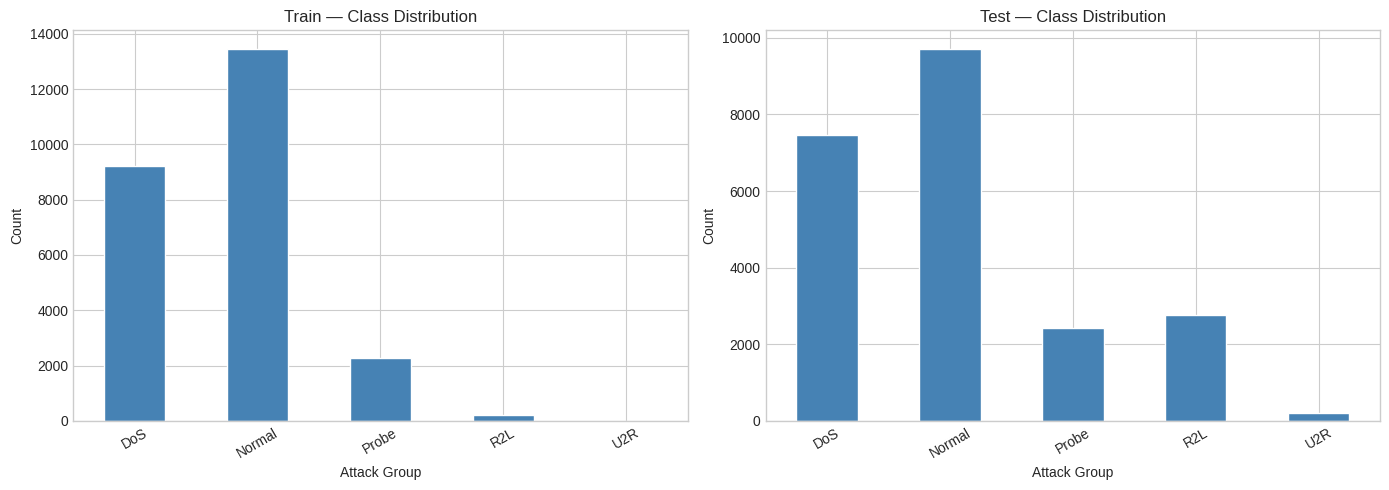

Train class counts:
attack
Normal    13449
DoS        9234
Probe      2289
R2L         209
U2R          11
Name: count, dtype: int64
Test class counts:
attack
Normal    9711
DoS       7458
R2L       2754
Probe     2421
U2R        200
Name: count, dtype: int64


In [7]:
# --- 5a. Class distribution ---
label_names = dict(enumerate(le.classes_))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (y, title) in zip(axes, [(y_train, "Train"), (y_test, "Test")]):
    counts = y.value_counts().sort_index()
    counts.index = [label_names[i] for i in counts.index]
    counts.plot(kind="bar", ax=ax, color="steelblue", edgecolor="white")
    ax.set_title(f"{title} — Class Distribution")
    ax.set_xlabel("Attack Group")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

print("Train class counts:")
print(y_train.map(label_names).value_counts())
print("Test class counts:")
print(y_test.map(label_names).value_counts())


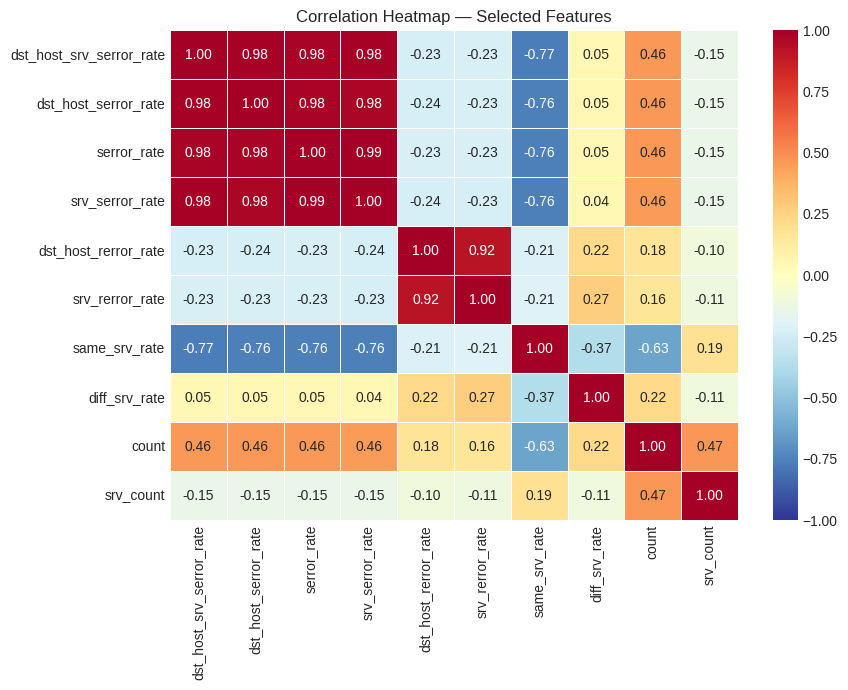

In [8]:
# --- 5c. Correlation heatmap (selected numeric features) ---
CORR_FEATURES = [
    "dst_host_srv_serror_rate", "dst_host_serror_rate", "serror_rate",
    "srv_serror_rate", "dst_host_rerror_rate", "srv_rerror_rate",
    "same_srv_rate", "diff_srv_rate", "count", "srv_count",
]

# Resolve column names robustly
resolved = []
for feat in CORR_FEATURES:
    if feat in X_train.columns:
        resolved.append(feat)
    else:
        match = next((c for c in X_train.columns if c.endswith(feat)), None)
        if match:
            resolved.append(match)

corr = X_train[resolved].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap="RdYlBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap — Selected Features")
plt.tight_layout()
plt.show()


In [9]:
from sklearn.feature_selection import VarianceThreshold

# ── Missing Value Filter ──────────────────────────────────────────────────
missing_threshold = 0.30   # drop features with >30% missing values
missing_ratio = X_train.isnull().mean()
cols_to_drop_missing = missing_ratio[missing_ratio > missing_threshold].index.tolist()

print(f"Features dropped due to >{missing_threshold*100:.0f}% missing values: {len(cols_to_drop_missing)}")
print(cols_to_drop_missing)

X_train_basic = X_train.drop(columns=cols_to_drop_missing)
X_test_basic  = X_test.drop(columns=cols_to_drop_missing)



Features dropped due to >30% missing values: 0
[]


In [10]:
print("--- Final Check ---")
print(f"Training Features (X): {X_train.shape}")
print(f"Training Target (y): {y_train.shape}")

print(f"Training Features (X): {X_test.shape}")
print(f"Training Target (y): {y_test.shape}")

--- Final Check ---
Training Features (X): (25192, 117)
Training Target (y): (25192,)
Training Features (X): (22544, 117)
Training Target (y): (22544,)


## Mutual Information on NSL-KDD

Top 20 Features by Mutual Information:
src_bytes                      0.714311
diff_srv_rate                  0.499436
same_srv_rate                  0.459927
dst_bytes                      0.455137
dst_host_diff_srv_rate         0.453973
count                          0.417362
dst_host_srv_count             0.413943
dst_host_same_srv_rate         0.404461
dst_host_serror_rate           0.398806
serror_rate                    0.379417
flag_SF                        0.373996
dst_host_srv_serror_rate       0.370489
flag_S0                        0.357551
srv_serror_rate                0.357021
logged_in                      0.309784
dst_host_srv_diff_host_rate    0.260810
dst_host_same_src_port_rate    0.239276
dst_host_count                 0.201419
service_http                   0.188856
srv_count                      0.159669
srv_diff_host_rate             0.149745
service_private                0.116710
dst_host_rerror_rate           0.096799
dst_host_srv_rerror_rate       0.083441
s

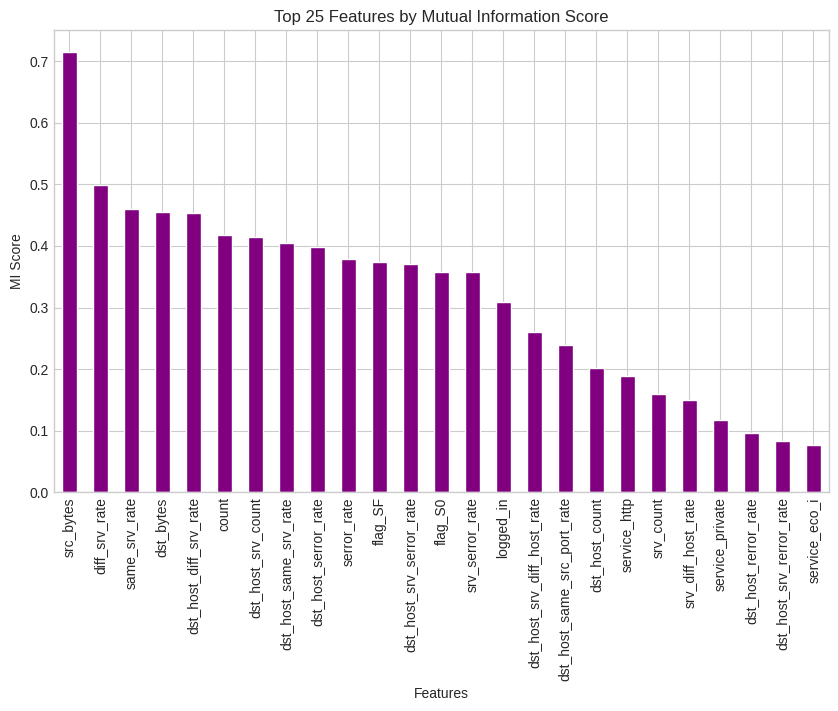

In [11]:
#MI ranks features
mi_scores_values = mutual_info_classif(X_train, y_train, random_state=42)
mi_scores = pd.Series(mi_scores_values, index=X_train.columns).sort_values(ascending=False)

#Report: top 25 features by MI score
print("Top 20 Features by Mutual Information:")
print(mi_scores.head(50))


import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
mi_scores.head(25).plot(kind='bar', color='purple')
plt.title("Top 25 Features by Mutual Information Score")
plt.ylabel("MI Score")
plt.xlabel("Features")
plt.show()

In [12]:
#Apply Pearson on MI top 50 features
top_50_features = mi_scores.head(50).index.tolist()

#a dataframe of just these candidates
df_candidates = X_train[top_50_features]

#Correlation Matrix
corr_matrix = df_candidates.corr().abs()

#Identify redundant pairs (Correlation > 0.90)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if any(upper[col] > 0.90)]

final_pool = top_50_features.copy()
to_drop = set()

# 2. Re-examine the redundant pairs
for col in upper.columns:
    # Find features highly correlated with 'col'
    high_corr_features = upper.index[upper[col] > 0.90].tolist()

    for feature in high_corr_features:

        score_feature = mi_scores[feature]
        score_col = mi_scores[col]


        if score_feature < score_col:
            weaker_feature = feature
        else:
            weaker_feature = col

        to_drop.add(weaker_feature)


final_pool = [f for f in final_pool if f not in to_drop]

print(f"Redundant Features Dropped (Lower MI): {to_drop}")
print(f"Remaining High-Signal Features final_pool after Filter: {len(final_pool)}")
print(f"Final Selection: {final_pool}")


Redundant Features Dropped (Lower MI): {'flag_S0', 'serror_rate', 'dst_host_srv_rerror_rate', 'srv_serror_rate', 'rerror_rate', 'dst_host_srv_serror_rate', 'srv_rerror_rate'}
Remaining High-Signal Features final_pool after Filter: 43
Final Selection: ['src_bytes', 'diff_srv_rate', 'same_srv_rate', 'dst_bytes', 'dst_host_diff_srv_rate', 'count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_serror_rate', 'flag_SF', 'logged_in', 'dst_host_srv_diff_host_rate', 'dst_host_same_src_port_rate', 'dst_host_count', 'service_http', 'srv_count', 'srv_diff_host_rate', 'service_private', 'dst_host_rerror_rate', 'service_eco_i', 'duration', 'service_domain_u', 'protocol_type_icmp', 'protocol_type_udp', 'protocol_type_tcp', 'flag_RSTR', 'service_smtp', 'hot', 'flag_REJ', 'service_other', 'service_ecr_i', 'service_ftp_data', 'service_uucp', 'is_guest_login', 'service_bgp', 'wrong_fragment', 'service_domain', 'service_ctf', 'service_nnsp', 'service_netbios_ns', 'service_iso_tsap', 'service_e

In [13]:
# Filter the dataframes
X_train_final = X_train[final_pool]
X_test_final = X_test[final_pool]

print(f"Final training shape: {X_train_final.shape}")
print(f"Final testing shape: {X_test_final.shape}")

Final training shape: (25192, 43)
Final testing shape: (22544, 43)


In [14]:

final_ranked_features = mi_scores[final_pool].sort_values(ascending=False)


top_30_final = final_ranked_features.head(30)


print("\n" + "="*30)
print("FINAL TOP 30 FEATURES (Redundancy-Free)")
print("="*30)
for i, (feature, score) in enumerate(top_30_final.items(), 1):
    print(f"{i}. {feature:<25} (MI Score: {score:.4f})")


final_feature_list = top_30_final.index.tolist()


FINAL TOP 30 FEATURES (Redundancy-Free)
1. src_bytes                 (MI Score: 0.7143)
2. diff_srv_rate             (MI Score: 0.4994)
3. same_srv_rate             (MI Score: 0.4599)
4. dst_bytes                 (MI Score: 0.4551)
5. dst_host_diff_srv_rate    (MI Score: 0.4540)
6. count                     (MI Score: 0.4174)
7. dst_host_srv_count        (MI Score: 0.4139)
8. dst_host_same_srv_rate    (MI Score: 0.4045)
9. dst_host_serror_rate      (MI Score: 0.3988)
10. flag_SF                   (MI Score: 0.3740)
11. logged_in                 (MI Score: 0.3098)
12. dst_host_srv_diff_host_rate (MI Score: 0.2608)
13. dst_host_same_src_port_rate (MI Score: 0.2393)
14. dst_host_count            (MI Score: 0.2014)
15. service_http              (MI Score: 0.1889)
16. srv_count                 (MI Score: 0.1597)
17. srv_diff_host_rate        (MI Score: 0.1497)
18. service_private           (MI Score: 0.1167)
19. dst_host_rerror_rate      (MI Score: 0.0968)
20. service_eco_i             (MI

In [15]:
X_train_Filter = X_train_final[final_feature_list]
X_test_Filter = X_test_final[final_feature_list]

print(f"Final training shape: {X_train_Filter.shape}")
print(f"Final testing shape: {X_test_Filter.shape}")

Final training shape: (25192, 30)
Final testing shape: (22544, 30)


In [16]:
print(f"Top 10: {final_feature_list[:10]}")
print(f"\nTop 20: {final_feature_list[:20]}")
print(f"\nTop 30: {final_feature_list[:30]}")

Top 10: ['src_bytes', 'diff_srv_rate', 'same_srv_rate', 'dst_bytes', 'dst_host_diff_srv_rate', 'count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_serror_rate', 'flag_SF']

Top 20: ['src_bytes', 'diff_srv_rate', 'same_srv_rate', 'dst_bytes', 'dst_host_diff_srv_rate', 'count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_serror_rate', 'flag_SF', 'logged_in', 'dst_host_srv_diff_host_rate', 'dst_host_same_src_port_rate', 'dst_host_count', 'service_http', 'srv_count', 'srv_diff_host_rate', 'service_private', 'dst_host_rerror_rate', 'service_eco_i']

Top 30: ['src_bytes', 'diff_srv_rate', 'same_srv_rate', 'dst_bytes', 'dst_host_diff_srv_rate', 'count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_serror_rate', 'flag_SF', 'logged_in', 'dst_host_srv_diff_host_rate', 'dst_host_same_src_port_rate', 'dst_host_count', 'service_http', 'srv_count', 'srv_diff_host_rate', 'service_private', 'dst_host_rerror_rate', 'service_eco_i', 'duration', 'service_domain_u

In [17]:

warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
warnings.filterwarnings("ignore")

from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

# 1. Initialize the Internal Estimator

rf_engine = RandomForestClassifier(n_estimators=20, max_depth=8, n_jobs=-1, random_state=42)

# 2. Initialize RFECV

selector = RFECV(
    estimator=rf_engine,
    step=5,
    cv=StratifiedKFold(3),
    scoring='f1_weighted',
    min_features_to_select=5,
    n_jobs=-1,
    verbose=1
)


print("Starting RFECV optimization...")
selector.fit(X_train, y_train)
warnings.filterwarnings("ignore")
X_train_rfe = selector.transform(X_train)
X_test_rfe  = selector.transform(X_test)

optimal_feature_count = selector.n_features_
optimal_features_rfecv = X_train.columns[selector.support_].tolist()

print(f"\n--- RFECV Results ---")
print(f"Optimal number of features: {optimal_feature_count}")
print(f"Selected Subset: {optimal_features_rfecv}")

warnings.filterwarnings("ignore")


Starting RFECV optimization...
Fitting estimator with 117 features.
Fitting estimator with 117 features.
Fitting estimator with 112 features.
Fitting estimator with 117 features.


/home/ayat/PycharmProjects/NSL-KDD/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ayat/PycharmProjects/NSL-KDD/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ayat/PycharmProjects/NSL-KDD/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ayat/PycharmP

Fitting estimator with 112 features.


/home/ayat/PycharmProjects/NSL-KDD/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ayat/PycharmProjects/NSL-KDD/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ayat/PycharmProjects/NSL-KDD/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ayat/PycharmP

Fitting estimator with 112 features.
Fitting estimator with 107 features.


...

Fitting estimator with 57 features.
Fitting estimator with 52 features.
Fitting estimator with 57 features.


/home/ayat/PycharmProjects/NSL-KDD/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ayat/PycharmProjects/NSL-KDD/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ayat/PycharmProjects/NSL-KDD/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ayat/PycharmP

Fitting estimator with 47 features.
Fitting estimator with 52 features.
Fitting estimator with 52 features.


/home/ayat/PycharmProjects/NSL-KDD/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ayat/PycharmProjects/NSL-KDD/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ayat/PycharmProjects/NSL-KDD/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ayat/PycharmP

Fitting estimator with 42 features.
Fitting estimator with 47 features.
Fitting estimator with 47 features.
Fitting estimator with 37 features.
Fitting estimator with 42 features.
Fitting estimator with 42 features.
Fitting estimator with 32 features.
Fitting estimator with 37 features.
Fitting estimator with 37 features.
Fitting estimator with 27 features.
Fitting estimator with 32 features.
Fitting estimator with 32 features.
Fitting estimator with 22 features.
Fitting estimator with 27 features.
Fitting estimator with 27 features.
Fitting estimator with 17 features.
Fitting estimator with 22 features.
Fitting estimator with 22 features.
Fitting estimator with 12 features.
Fitting estimator with 17 features.
Fitting estimator with 17 features.
Fitting estimator with 7 features.
Fitting estimator with 12 features.
Fitting estimator with 12 features.
Fitting estimator with 7 features.
Fitting estimator with 7 features.
Fitting estimator with 117 features.
Fitting estimator with 112 fea

In [18]:
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
warnings.filterwarnings("ignore")

from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.ensemble import RandomForestClassifier


clf = RandomForestClassifier(
    n_estimators=10,
    max_depth=5,
    min_samples_leaf=10,
    n_jobs=-1,
    random_state=42
)

# 2. Initialize SFS
sfs = SequentialFeatureSelector(
    estimator=clf,
    n_features_to_select=15,
    direction='forward',
    scoring='f1_weighted',
    cv=3,
    n_jobs=-1
)


sfs.fit(X_train, y_train)

X_train_sfs = sfs.transform(X_train)
X_test_sfs  = sfs.transform(X_test)
# 4. Extract the results
optimal_features_sfs = X_train.columns[sfs.get_support()].tolist()

print(f"SFS Selected {len(optimal_features_sfs)} Features: {optimal_features_sfs}")

SFS Selected 15 Features: ['duration', 'src_bytes', 'dst_bytes', 'count', 'srv_serror_rate', 'diff_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'protocol_type_icmp', 'service_bgp', 'service_exec', 'service_ftp_data', 'service_netstat', 'service_private', 'flag_SF']


### All features: X_train
### Filter features: X_test_Filter
### Wrapper features: optimal_features_sfs , optimal_features_rfecv

In [19]:

all_classes = [0, 1, 2, 3, 4]
CLASS_NAMES = ['DoS', 'Normal', 'Probe', 'R2L', 'U2R']

RF_RESULTS = {}
SVM_RESULTS = {}
XGB_RESULTS = {}

In [20]:
from sklearn.metrics import accuracy_score

from sklearn.metrics import f1_score

from sklearn.metrics import classification_report

from sklearn.metrics import confusion_matrix


def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average='weighted')
    f1_mac = f1_score(y_true, y_pred, average='macro')
    print(f'\n=== {name} ===')
    print(f'Accuracy : {acc:.4f}   Weighted F1 : {f1:.4f}, Macro F1: {f1_mac:.4f}')
    print(classification_report(y_true, y_pred,
                                labels=all_classes,
                                target_names=CLASS_NAMES))
    cm = confusion_matrix(y_true, y_pred, labels=all_classes)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f'{name} — Confusion Matrix')
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    plt.tight_layout(); plt.show()
    return acc, f1, f1_mac



In [21]:
def _make_rf():
    return RandomForestClassifier(
        n_estimators=100, max_depth=15, min_samples_split=10,
        class_weight='balanced', n_jobs=-1, random_state=42)

## Random Forest Training


>>> Training Random Forest on: Full Dataset (K=117)

=== Full Dataset ===
Accuracy : 0.7489   Weighted F1 : 0.7163, Macro F1: 0.5153
              precision    recall  f1-score   support

         DoS       0.96      0.76      0.85      7458
      Normal       0.65      0.97      0.78      9711
       Probe       0.84      0.59      0.69      2421
         R2L       0.98      0.12      0.21      2754
         U2R       0.71      0.03      0.05       200

    accuracy                           0.75     22544
   macro avg       0.83      0.49      0.52     22544
weighted avg       0.81      0.75      0.72     22544



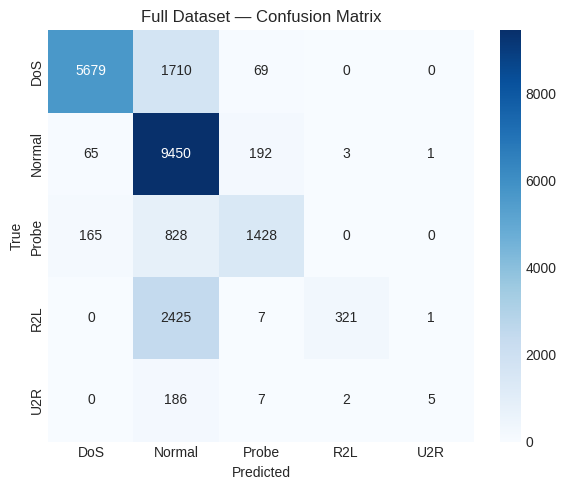


>>> Training Random Forest on: Filter (MI Top 30) (K=30)

=== Filter (MI Top 30) ===
Accuracy : 0.7385   Weighted F1 : 0.6920, Macro F1: 0.4758
              precision    recall  f1-score   support

         DoS       0.96      0.77      0.85      7458
      Normal       0.64      0.97      0.77      9711
       Probe       0.85      0.61      0.71      2421
         R2L       0.97      0.01      0.02      2754
         U2R       0.50      0.01      0.03       200

    accuracy                           0.74     22544
   macro avg       0.78      0.47      0.48     22544
weighted avg       0.81      0.74      0.69     22544



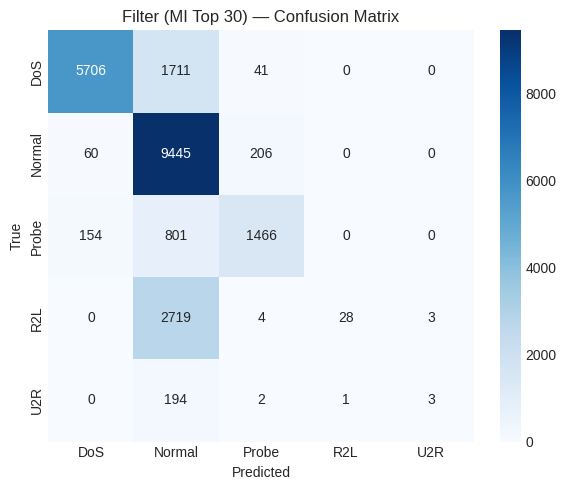


>>> Training Random Forest on: Wrapper 1 (RFECV) (K=37)

=== Wrapper 1 (RFECV) ===
Accuracy : 0.7452   Weighted F1 : 0.7077, Macro F1: 0.5020
              precision    recall  f1-score   support

         DoS       0.96      0.77      0.85      7458
      Normal       0.64      0.97      0.77      9711
       Probe       0.85      0.59      0.69      2421
         R2L       0.98      0.08      0.14      2754
         U2R       0.71      0.03      0.05       200

    accuracy                           0.75     22544
   macro avg       0.83      0.49      0.50     22544
weighted avg       0.81      0.75      0.71     22544



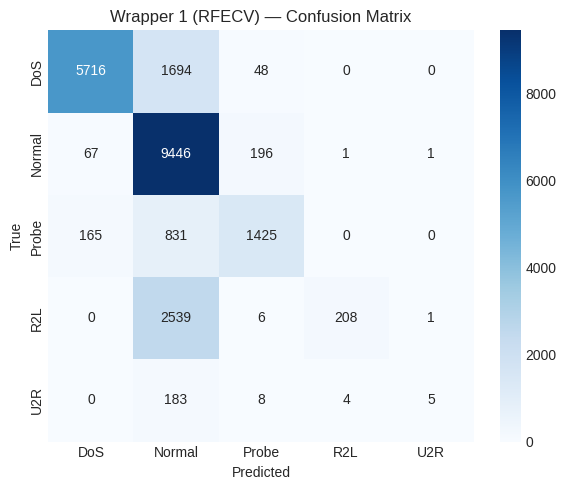


>>> Training Random Forest on: Wrapper 2 (SFS) (K=15)

=== Wrapper 2 (SFS) ===
Accuracy : 0.7583   Weighted F1 : 0.7220, Macro F1: 0.5192
              precision    recall  f1-score   support

         DoS       0.95      0.79      0.86      7458
      Normal       0.66      0.97      0.78      9711
       Probe       0.84      0.64      0.73      2421
         R2L       0.99      0.09      0.16      2754
         U2R       0.75      0.03      0.06       200

    accuracy                           0.76     22544
   macro avg       0.84      0.50      0.52     22544
weighted avg       0.82      0.76      0.72     22544



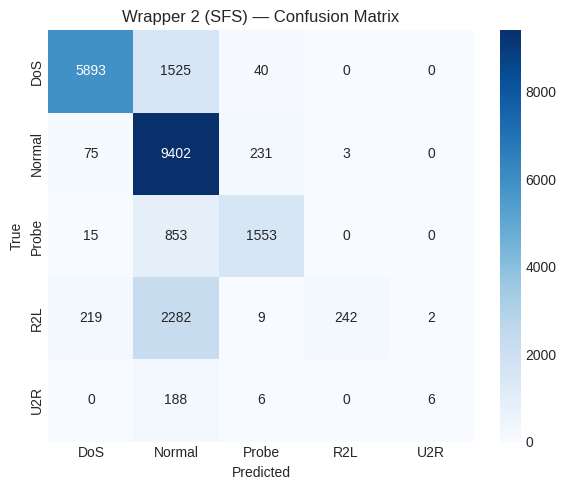


--- FINAL COMPARISON SUMMARY ---
                    Accuracy  Weighted F1  Macro F1      K
Full Dataset        0.748891     0.716258  0.515289  117.0
Filter (MI Top 30)  0.738467     0.692003  0.475797   30.0
Wrapper 1 (RFECV)   0.745209     0.707705  0.501970   37.0
Wrapper 2 (SFS)     0.758339     0.722009  0.519155   15.0


In [22]:

FEATURE_SUBSETS = {
    "Full Dataset": X_train.columns.tolist(),
    "Filter (MI Top 30)": final_feature_list,
    "Wrapper 1 (RFECV)": optimal_features_rfecv,
    "Wrapper 2 (SFS)": optimal_features_sfs
}

for name, f_list in FEATURE_SUBSETS.items():
    print(f"\n>>> Training Random Forest on: {name} (K={len(f_list)})")

    clf = _make_rf()


    clf.fit(X_train[f_list], y_train)
    y_pred = clf.predict(X_test[f_list])

    # Evaluate and store
    acc, f1, f1_mac = evaluate(name, y_test, y_pred)
    RF_RESULTS[name] = {'Accuracy': acc, 'Weighted F1': f1, 'Macro F1': f1_mac, 'K': len(f_list)}

# Final Comparison Table

summary_df = pd.DataFrame(RF_RESULTS).T
print("\n--- FINAL COMPARISON SUMMARY ---")
print(summary_df)


── SVM: Baseline (All Features) ──

=== SVM (Linear) - Baseline ===
Accuracy : 0.7399   Weighted F1 : 0.6961, Macro F1: 0.4843
              precision    recall  f1-score   support

         DoS       0.93      0.82      0.87      7458
      Normal       0.65      0.93      0.76      9711
       Probe       0.78      0.63      0.70      2421
         R2L       0.30      0.02      0.03      2754
         U2R       0.86      0.03      0.06       200

    accuracy                           0.74     22544
   macro avg       0.70      0.48      0.48     22544
weighted avg       0.72      0.74      0.70     22544



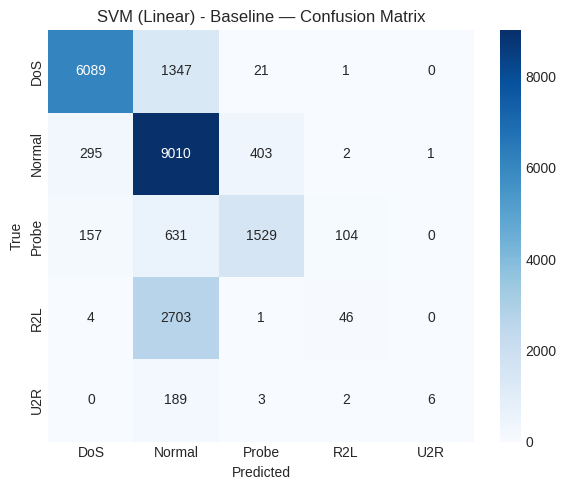


── SVM: Filter-based (MI) top-30 features ──

=== SVM (Linear) (MI, K=30) ===
Accuracy : 0.7247   Weighted F1 : 0.6771, Macro F1: 0.4613
              precision    recall  f1-score   support

         DoS       0.89      0.78      0.83      7458
      Normal       0.63      0.93      0.75      9711
       Probe       0.86      0.62      0.72      2421
         R2L       0.40      0.00      0.01      2754
         U2R       0.00      0.00      0.00       200

    accuracy                           0.72     22544
   macro avg       0.56      0.47      0.46     22544
weighted avg       0.71      0.72      0.68     22544



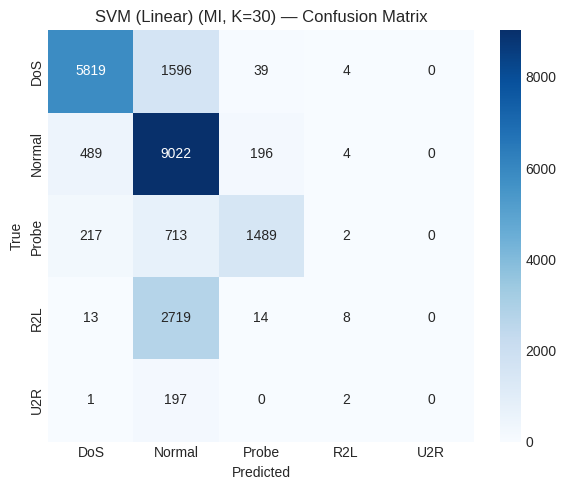


── SVM: Wrapper 1 (RFECV) top-25 features ──

=== SVM (Linear) (RFECV, K=25) ===
Accuracy : 0.7308   Weighted F1 : 0.6844, Macro F1: 0.4525
              precision    recall  f1-score   support

         DoS       0.97      0.82      0.89      7458
      Normal       0.63      0.93      0.75      9711
       Probe       0.68      0.56      0.62      2421
         R2L       0.79      0.00      0.01      2754
         U2R       0.00      0.00      0.00       200

    accuracy                           0.73     22544
   macro avg       0.61      0.46      0.45     22544
weighted avg       0.76      0.73      0.68     22544



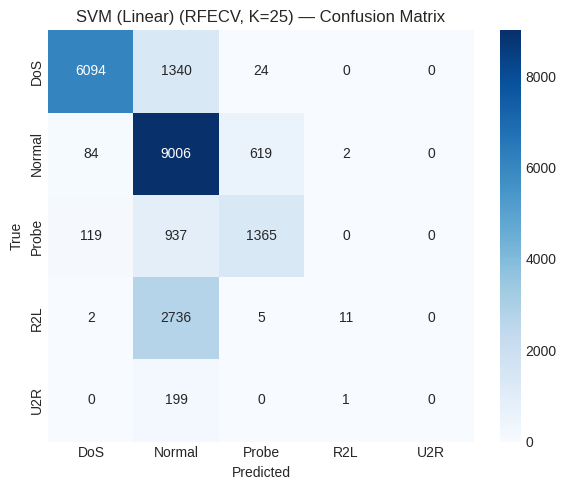


── SVM: Wrapper 2 (SFS) top-15 features ──

=== SVM (Linear) (SFS, K=15) ===
Accuracy : 0.7031   Weighted F1 : 0.6542, Macro F1: 0.4329
              precision    recall  f1-score   support

         DoS       0.88      0.75      0.81      7458
      Normal       0.63      0.92      0.74      9711
       Probe       0.70      0.54      0.61      2421
         R2L       0.00      0.00      0.00      2754
         U2R       0.00      0.00      0.00       200

    accuracy                           0.70     22544
   macro avg       0.44      0.44      0.43     22544
weighted avg       0.63      0.70      0.65     22544



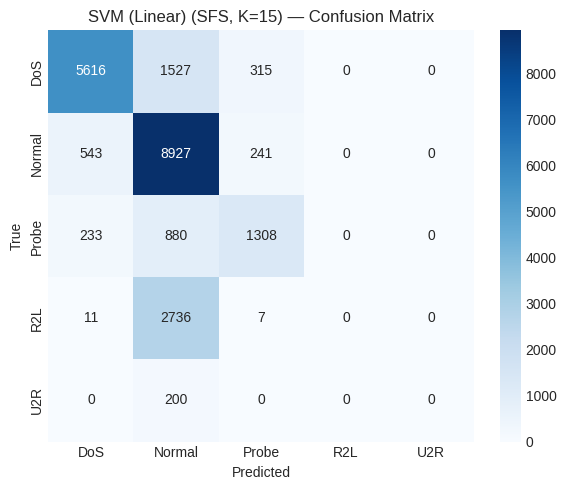


--- UNIFIED EVALUATION SUMMARY ---
                            Accuracy  Weighted F1  Macro F1      K
SVM (Linear) - Baseline     0.739886     0.696128  0.484322  117.0
SVM (Linear) (MI, K=30)     0.724716     0.677090  0.461284   30.0
SVM (Linear) (RFECV, K=25)  0.730837     0.684423  0.452464   37.0
SVM (Linear) (SFS, K=15)    0.703114     0.654230  0.432869   15.0


In [23]:
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
import pandas as pd

# 1. Professor's Model Factory (Linear Only)
def _make_linear_svc():
    return Pipeline([
        ('clf', LinearSVC(C=1.0, max_iter=2000, random_state=42, dual='auto')),
    ])

# 2. Baseline Evaluation (K=117)
print(f'── SVM: Baseline (All Features) ──')
K_baseline = X_train.shape[1]
clf = _make_linear_svc()
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
label = 'SVM (Linear) - Baseline'
acc, f1, macro = evaluate(label, y_test, y_pred)

SVM_RESULTS[label] = {
    'Accuracy': acc,
    'Weighted F1': f1,
    'Macro F1': macro,
    'K': K_baseline
}

# 3. Filter-based Evaluation (K=30)
print(f'\n── SVM: Filter-based (MI) top-30 features ──')
K_mi = len(final_feature_list)
clf = _make_linear_svc()
clf.fit(X_train[final_feature_list], y_train)
y_pred = clf.predict(X_test[final_feature_list])
label = 'SVM (Linear) (MI, K=30)'
acc, f1, macro = evaluate(label, y_test, y_pred)

SVM_RESULTS[label] = {
    'Accuracy': acc,
    'Weighted F1': f1,
    'Macro F1': macro,
    'K': K_mi
}

# 4. Wrapper 1: RFECV Evaluation (K=25)
print(f'\n── SVM: Wrapper 1 (RFECV) top-25 features ──')
K_rfecv = len(optimal_features_rfecv)
clf = _make_linear_svc()
clf.fit(X_train[optimal_features_rfecv], y_train)
y_pred = clf.predict(X_test[optimal_features_rfecv])
label = 'SVM (Linear) (RFECV, K=25)'
acc, f1, macro = evaluate(label, y_test, y_pred)

SVM_RESULTS[label] = {
    'Accuracy': acc,
    'Weighted F1': f1,
    'Macro F1': macro,
    'K': K_rfecv
}

# 5. Wrapper 2: SFS Evaluation (K=15)
print(f'\n── SVM: Wrapper 2 (SFS) top-15 features ──')
K_sfs = len(optimal_features_sfs)
clf = _make_linear_svc()
clf.fit(X_train[optimal_features_sfs], y_train)
y_pred = clf.predict(X_test[optimal_features_sfs])
label = 'SVM (Linear) (SFS, K=15)'
acc, f1, macro = evaluate(label, y_test, y_pred)

SVM_RESULTS[label] = {
    'Accuracy': acc,
    'Weighted F1': f1,
    'Macro F1': macro,
    'K': K_sfs
}

# Final Clean Summary Table
summary_df = pd.DataFrame(SVM_RESULTS).T
summary_df = summary_df.sort_values(by='Macro F1', ascending=False)
print("\n--- UNIFIED EVALUATION SUMMARY ---")
print(summary_df)

── Starting XGBoost Subset Evaluations ──

>>> Training: XGBoost - Baseline (K=117)

=== XGBoost - Baseline ===
Accuracy : 0.7746   Weighted F1 : 0.7386, Macro F1: 0.5248
              precision    recall  f1-score   support

         DoS       0.96      0.84      0.90      7458
      Normal       0.67      0.97      0.80      9711
       Probe       0.85      0.60      0.71      2421
         R2L       0.99      0.10      0.19      2754
         U2R       0.80      0.02      0.04       200

    accuracy                           0.77     22544
   macro avg       0.86      0.51      0.52     22544
weighted avg       0.83      0.77      0.74     22544



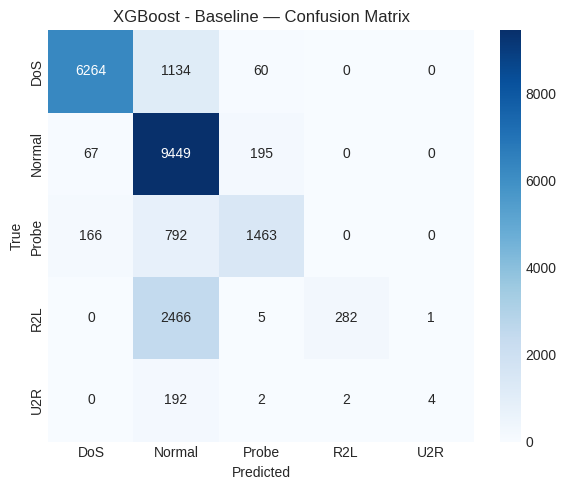


>>> Training: XGBoost (MI, K=30) (K=30)

=== XGBoost (MI, K=30) ===
Accuracy : 0.7664   Weighted F1 : 0.7250, Macro F1: 0.5071
              precision    recall  f1-score   support

         DoS       0.96      0.84      0.90      7458
      Normal       0.66      0.97      0.79      9711
       Probe       0.86      0.60      0.70      2421
         R2L       0.99      0.06      0.11      2754
         U2R       0.80      0.02      0.04       200

    accuracy                           0.77     22544
   macro avg       0.85      0.50      0.51     22544
weighted avg       0.82      0.77      0.72     22544



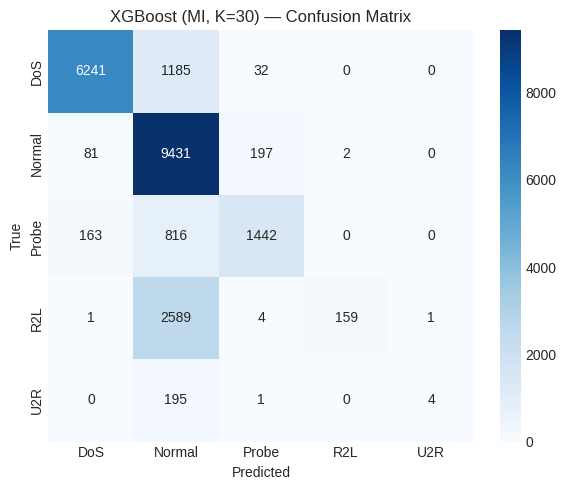


>>> Training: XGBoost (RFECV, K=25) (K=37)

=== XGBoost (RFECV, K=25) ===
Accuracy : 0.7694   Weighted F1 : 0.7337, Macro F1: 0.5229
              precision    recall  f1-score   support

         DoS       0.96      0.83      0.89      7458
      Normal       0.67      0.97      0.79      9711
       Probe       0.85      0.60      0.70      2421
         R2L       0.99      0.10      0.18      2754
         U2R       0.83      0.03      0.05       200

    accuracy                           0.77     22544
   macro avg       0.86      0.50      0.52     22544
weighted avg       0.83      0.77      0.73     22544



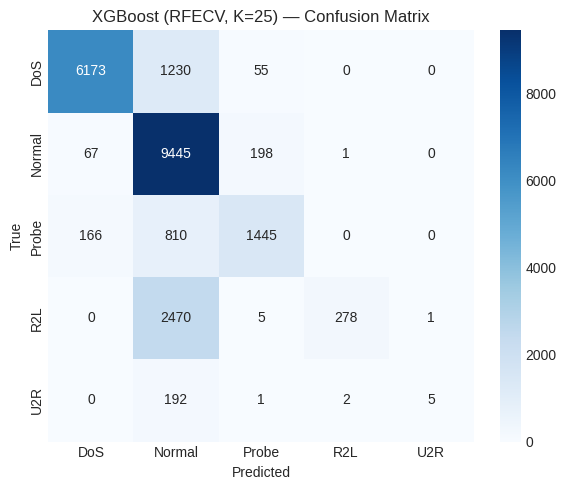


>>> Training: XGBoost (SFS, K=15) (K=15)

=== XGBoost (SFS, K=15) ===
Accuracy : 0.7597   Weighted F1 : 0.7197, Macro F1: 0.5073
              precision    recall  f1-score   support

         DoS       0.98      0.81      0.89      7458
      Normal       0.66      0.97      0.78      9711
       Probe       0.80      0.63      0.70      2421
         R2L       0.99      0.06      0.11      2754
         U2R       1.00      0.03      0.06       200

    accuracy                           0.76     22544
   macro avg       0.89      0.50      0.51     22544
weighted avg       0.82      0.76      0.72     22544



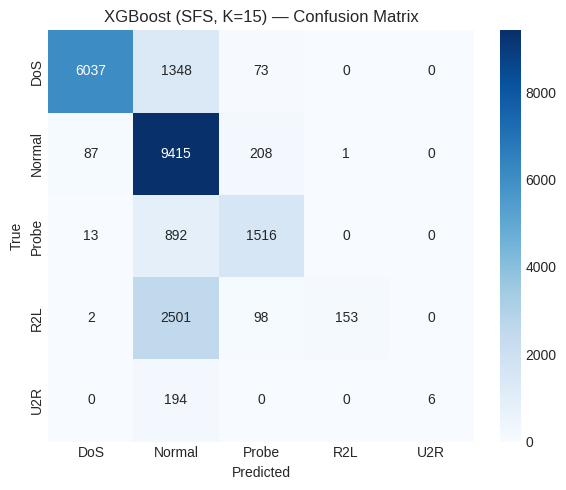


XGBOOST FEATURE SUBSET SUMMARY
                       Accuracy  Weighted F1  Macro F1      K
XGBoost - Baseline     0.774574     0.738648  0.524812  117.0
XGBoost (RFECV, K=25)  0.769429     0.733706  0.522924   37.0
XGBoost (SFS, K=15)    0.759714     0.719686  0.507313   15.0
XGBoost (MI, K=30)     0.766368     0.724974  0.507102   30.0


In [24]:
import xgboost as xgb
import pandas as pd

# 1. XGBoost Model Factory
def _make_xgb():
    return xgb.XGBClassifier(
        verbosity=0,
        random_state=42,
        eval_metric='mlogloss',
        n_estimators=100,
        max_depth=4,          # shallower trees
        learning_rate=0.1,
        subsample=0.8,        # use 80% of rows per tree
        colsample_bytree=0.8, # use 80% of features per tree
        tree_method='hist',   # fastest tree method for large datasets
        n_jobs=-1
    )

# 2. Setup Subsets and Temporary Dictionary
# This uses your specific notebook variables
XGB_RESULTS = {}
XGB_CONFIGS = [
    ("XGBoost - Baseline", X_train.columns.tolist()),
    ("XGBoost (MI, K=30)", final_feature_list),      # From Cell 14
    ("XGBoost (RFECV, K=25)", optimal_features_rfecv), # From Cell 17
    ("XGBoost (SFS, K=15)", optimal_features_sfs)            # From Cell 99
]

# 3. Execution Loop
print("── Starting XGBoost Subset Evaluations ──")

for label, f_list in XGB_CONFIGS:
    K_val = len(f_list)
    print(f"\n>>> Training: {label} (K={K_val})")

    clf = _make_xgb()

    # Train on the specific subset using Pandas slicing
    clf.fit(X_train[f_list], y_train)
    y_pred = clf.predict(X_test[f_list])

    # Evaluate using the professor's logic
    acc, f1, macro = evaluate(label, y_test, y_pred)

    # Store in RESULTS (for global tracking) and XGB_RESULTS (for this specific view)
    # Using 'Weighted F1' and 'K' to match your RF metrics
    entry = {
        'Accuracy': acc,
        'Weighted F1': f1,
        'Macro F1': macro,
        'K': K_val
    }

    XGB_RESULTS[label] = entry

# 4. Display Summary Table for XGBoost only
xgb_summary_df = pd.DataFrame(XGB_RESULTS).T
# Sort by Macro F1 to see which subset handled rare classes best
xgb_summary_df = xgb_summary_df.sort_values(by='Macro F1', ascending=False)

print("\n" + "="*40)
print("XGBOOST FEATURE SUBSET SUMMARY")
print("="*40)
print(xgb_summary_df)

## XGBoost and GridSearchCV

In [25]:
# Common XGBoost parameters
xgb_params = {
    'n_estimators': [50, 100 ],
    'max_depth':    [4, 6],
    'learning_rate': [0.01, 0.1]
}

sCV = StratifiedKFold(n_splits=5, shuffle=True, random_state=1000)

In [26]:
RF_RESULTS_Gridsearch = {}
SVM_RESULTS_Gridsearch = {}
XGB_RESULTS_Gridsearch = {}

Running XGBoost: Full Dataset...

=== XGBoost - Full ===
Accuracy : 0.7691   Weighted F1 : 0.7321, Macro F1: 0.5212
              precision    recall  f1-score   support

         DoS       0.96      0.83      0.89      7458
      Normal       0.67      0.97      0.79      9711
       Probe       0.85      0.59      0.70      2421
         R2L       0.98      0.09      0.17      2754
         U2R       0.67      0.03      0.06       200

    accuracy                           0.77     22544
   macro avg       0.83      0.50      0.52     22544
weighted avg       0.82      0.77      0.73     22544



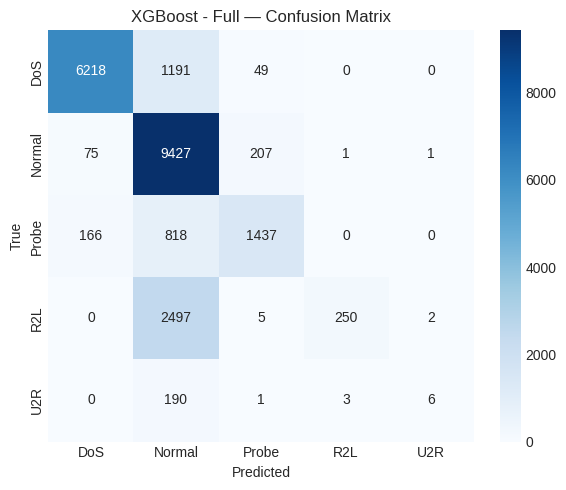

In [27]:
from sklearn.model_selection import GridSearchCV

from sklearn.feature_selection import SelectKBest

print("Running XGBoost: Full Dataset...")
grid_full = GridSearchCV(xgb.XGBClassifier(random_state=42), xgb_params, cv=sCV, scoring='f1_weighted', n_jobs=-1)
grid_full.fit(X_train, y_train)

y_pred = grid_full.predict(X_test)
acc, f1, macro = evaluate("XGBoost - Full", y_test, y_pred)
XGB_RESULTS_Gridsearch["XGBoost - Full"] = {'Accuracy': acc, 'Weighted F1': f1, 'Macro F1': macro, 'K': X_train.shape[1]}

Running XGBoost: Filter-based (MI)...

=== XGBoost (MI, K=30) ===
Accuracy : 0.7655   Weighted F1 : 0.7233, Macro F1: 0.5069
              precision    recall  f1-score   support

         DoS       0.96      0.84      0.89      7458
      Normal       0.67      0.97      0.79      9711
       Probe       0.82      0.60      0.69      2421
         R2L       1.00      0.05      0.10      2754
         U2R       1.00      0.03      0.06       200

    accuracy                           0.77     22544
   macro avg       0.89      0.50      0.51     22544
weighted avg       0.82      0.77      0.72     22544



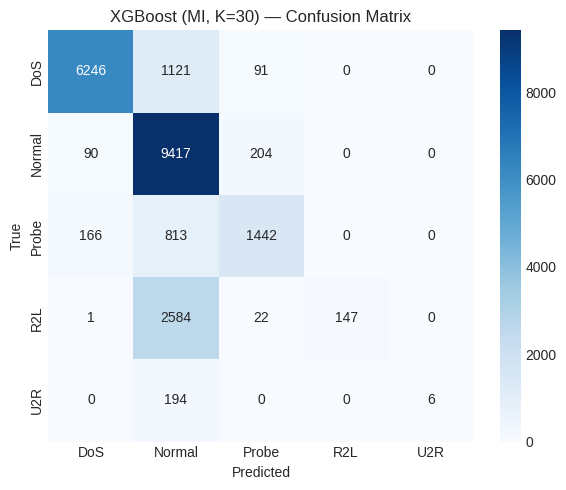

In [28]:

print("Running XGBoost: Filter-based (MI)...")
pipe_mi = Pipeline([
    ('selector', SelectKBest(score_func=mutual_info_classif)),
    ('clf',      xgb.XGBClassifier(random_state=42))
])

# Add 'selector__k' to the params
params_mi = {**{f'clf__{k}': v for k, v in xgb_params.items()}, 'selector__k': [10, 20, 30]}

grid_mi = GridSearchCV(pipe_mi, params_mi, cv=sCV, scoring='f1_weighted', n_jobs=-1)
grid_mi.fit(X_train, y_train)

y_pred = grid_mi.predict(X_test)
label = f"XGBoost (MI, K={grid_mi.best_params_['selector__k']})"
acc, f1, macro = evaluate(label, y_test, y_pred)
XGB_RESULTS_Gridsearch[label] = {'Accuracy': acc, 'Weighted F1': f1, 'Macro F1': macro, 'K': grid_mi.best_params_['selector__k']}

Running XGBoost: SFS-Selected...

=== XGBoost (SFS) ===
Accuracy : 0.7544   Weighted F1 : 0.7163, Macro F1: 0.5088
              precision    recall  f1-score   support

         DoS       0.98      0.79      0.88      7458
      Normal       0.65      0.97      0.78      9711
       Probe       0.82      0.62      0.71      2421
         R2L       0.98      0.07      0.13      2754
         U2R       0.86      0.03      0.06       200

    accuracy                           0.75     22544
   macro avg       0.86      0.50      0.51     22544
weighted avg       0.82      0.75      0.72     22544



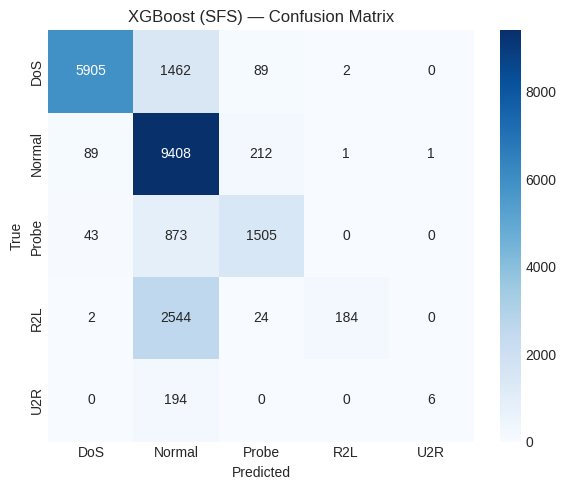

In [29]:
print("Running XGBoost: SFS-Selected...")
# Use your already defined list: optimal_features_sfs
grid_sfs = GridSearchCV(xgb.XGBClassifier(random_state=42), xgb_params, cv=sCV, scoring='f1_weighted', n_jobs=-1)
grid_sfs.fit(X_train[optimal_features_sfs], y_train)

y_pred = grid_sfs.predict(X_test[optimal_features_sfs])
label = "XGBoost (SFS)"
acc, f1, macro = evaluate(label, y_test, y_pred)
XGB_RESULTS_Gridsearch[label] = {'Accuracy': acc, 'Weighted F1': f1, 'Macro F1': macro, 'K': len(optimal_features_sfs)}

In [30]:
from sklearn.ensemble import RandomForestClassifier

# Define common RF parameters
rf_params = {
    'n_estimators': [50, 100],
    'max_depth': [8, 10],
    'min_samples_split': [5],
}

sCV = StratifiedKFold(n_splits=3, shuffle=True, random_state=1000)

Running Random Forest: Full Dataset...

=== RF - Full ===
Accuracy : 0.7365   Weighted F1 : 0.6898, Macro F1: 0.4678
              precision    recall  f1-score   support

         DoS       0.96      0.76      0.85      7458
      Normal       0.63      0.97      0.77      9711
       Probe       0.87      0.58      0.70      2421
         R2L       1.00      0.01      0.02      2754
         U2R       0.00      0.00      0.00       200

    accuracy                           0.74     22544
   macro avg       0.69      0.47      0.47     22544
weighted avg       0.81      0.74      0.69     22544



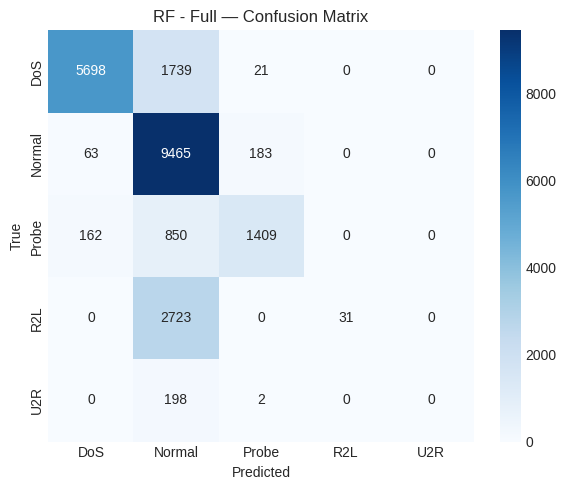

In [31]:
print("Running Random Forest: Full Dataset...")
grid_rf_full = GridSearchCV(RandomForestClassifier(random_state=42),
                            rf_params, cv=sCV, scoring='f1_weighted', n_jobs=-1)
grid_rf_full.fit(X_train, y_train)

y_pred = grid_rf_full.predict(X_test)
acc, f1, macro = evaluate("RF - Full", y_test, y_pred)
RF_RESULTS_Gridsearch["RF - Full"] = {'Accuracy': acc, 'Weighted F1': f1, 'Macro F1': macro, 'K': X_train.shape[1]}

Running Random Forest: Filter-based (MI)...

=== RF (MI, K=30) ===
Accuracy : 0.7560   Weighted F1 : 0.7140, Macro F1: 0.4918
              precision    recall  f1-score   support

         DoS       0.96      0.81      0.88      7458
      Normal       0.65      0.97      0.78      9711
       Probe       0.87      0.60      0.71      2421
         R2L       0.99      0.05      0.09      2754
         U2R       0.00      0.00      0.00       200

    accuracy                           0.76     22544
   macro avg       0.69      0.48      0.49     22544
weighted avg       0.81      0.76      0.71     22544



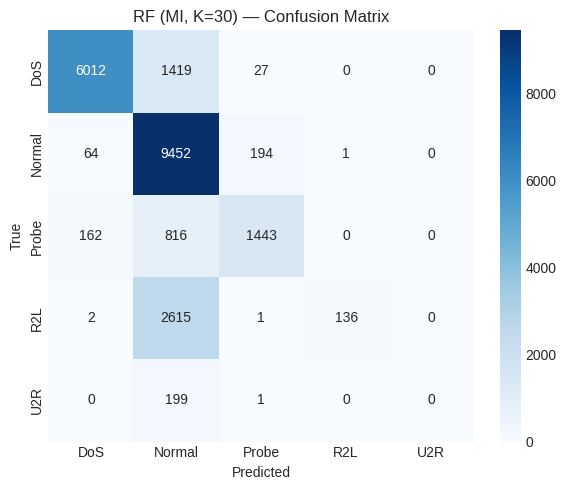

In [32]:
print("Running Random Forest: Filter-based (MI)...")
pipe_rf_mi = Pipeline([
    ('selector', SelectKBest(score_func=mutual_info_classif)),
    ('clf',      RandomForestClassifier(random_state=42))
])

# Update keys to match the pipeline structure
params_rf_mi = {**{f'clf__{k}': v for k, v in rf_params.items()},
                'selector__k': [10, 20, 30]}

grid_rf_mi = GridSearchCV(pipe_rf_mi, params_rf_mi, cv=sCV, scoring='f1_weighted', n_jobs=-1)
grid_rf_mi.fit(X_train, y_train)

best_k = grid_rf_mi.best_params_['selector__k']
y_pred = grid_rf_mi.predict(X_test)
label = f"RF (MI, K={best_k})"
acc, f1, macro = evaluate(label, y_test, y_pred)
RF_RESULTS_Gridsearch[label] = {'Accuracy': acc, 'Weighted F1': f1, 'Macro F1': macro, 'K': best_k}

Running Random Forest: SFS-Selected...

=== RF (SFS) ===
Accuracy : 0.7550   Weighted F1 : 0.7190, Macro F1: 0.5113
              precision    recall  f1-score   support

         DoS       0.96      0.79      0.87      7458
      Normal       0.65      0.97      0.78      9711
       Probe       0.85      0.61      0.71      2421
         R2L       0.99      0.09      0.16      2754
         U2R       1.00      0.02      0.04       200

    accuracy                           0.76     22544
   macro avg       0.89      0.49      0.51     22544
weighted avg       0.82      0.76      0.72     22544



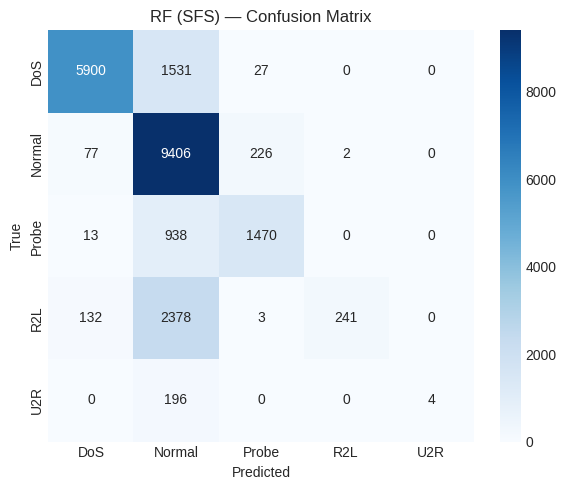

In [33]:
print("Running Random Forest: SFS-Selected...")
grid_rf_sfs = GridSearchCV(RandomForestClassifier(random_state=42),
                           rf_params, cv=sCV, scoring='f1_weighted', n_jobs=-1)

grid_rf_sfs.fit(X_train[optimal_features_sfs], y_train)

y_pred = grid_rf_sfs.predict(X_test[optimal_features_sfs])
label = "RF (SFS)"
acc, f1, macro = evaluate(label, y_test, y_pred)
RF_RESULTS_Gridsearch[label] = {'Accuracy': acc, 'Weighted F1': f1, 'Macro F1': macro, 'K': len(optimal_features_sfs)}

In [34]:

final_summary = pd.DataFrame(RF_RESULTS_Gridsearch).T
print(final_summary.sort_values(by='Macro F1', ascending=False))

               Accuracy  Weighted F1  Macro F1      K
RF (SFS)       0.755012     0.718992  0.511311   15.0
RF (MI, K=30)  0.755988     0.714040  0.491758   30.0
RF - Full      0.736471     0.689764  0.467793  117.0


## SVM with GridSearchCV

Starting LinearSVC Hyperparameter Tuning...
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best C: 10

=== SVM - Baseline ===
Accuracy : 0.7432   Weighted F1 : 0.7019, Macro F1: 0.5028
              precision    recall  f1-score   support

         DoS       0.91      0.82      0.86      7458
      Normal       0.65      0.93      0.77      9711
       Probe       0.84      0.63      0.72      2421
         R2L       0.42      0.03      0.06      2754
         U2R       0.69      0.06      0.10       200

    accuracy                           0.74     22544
   macro avg       0.70      0.49      0.50     22544
weighted avg       0.73      0.74      0.70     22544



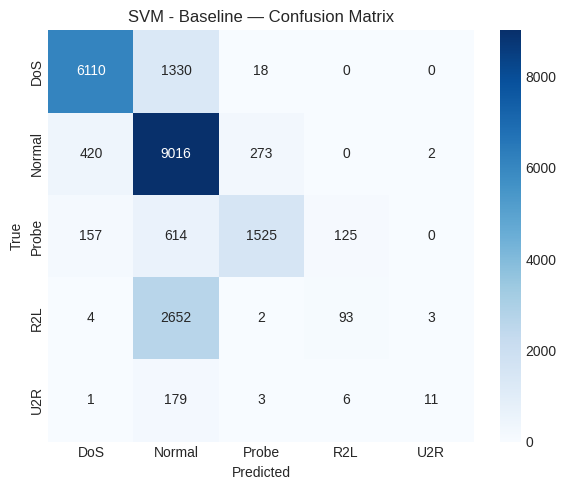


=== SVM (MI, K=30) ===
Accuracy : 0.7234   Weighted F1 : 0.6759, Macro F1: 0.4606
              precision    recall  f1-score   support

         DoS       0.89      0.78      0.83      7458
      Normal       0.63      0.93      0.75      9711
       Probe       0.86      0.62      0.72      2421
         R2L       0.60      0.00      0.01      2754
         U2R       0.00      0.00      0.00       200

    accuracy                           0.72     22544
   macro avg       0.60      0.46      0.46     22544
weighted avg       0.73      0.72      0.68     22544



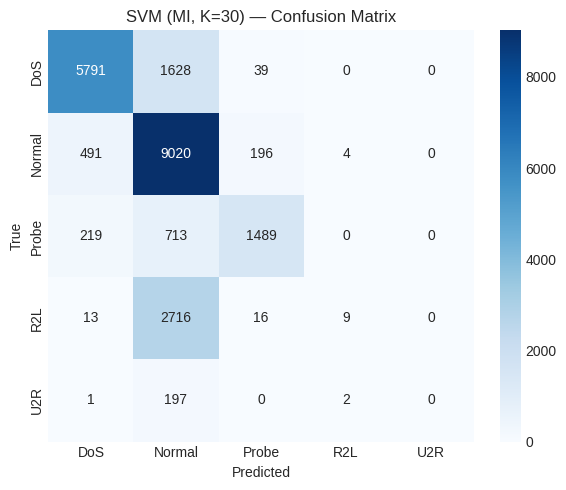


=== SVM (SFS, K=15) ===
Accuracy : 0.7020   Weighted F1 : 0.6532, Macro F1: 0.4321
              precision    recall  f1-score   support

         DoS       0.88      0.75      0.81      7458
      Normal       0.62      0.92      0.74      9711
       Probe       0.70      0.54      0.61      2421
         R2L       0.00      0.00      0.00      2754
         U2R       0.00      0.00      0.00       200

    accuracy                           0.70     22544
   macro avg       0.44      0.44      0.43     22544
weighted avg       0.63      0.70      0.65     22544



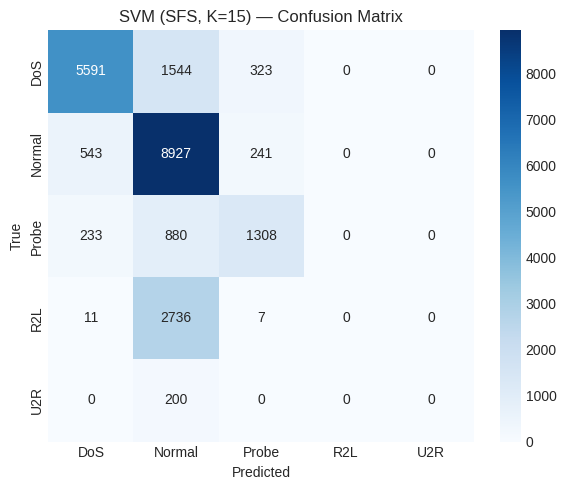


--- TUNED SVM SUMMARY ---
                 Accuracy  Weighted F1  Macro F1      K
SVM - Baseline   0.743213     0.701945  0.502834  117.0
SVM (MI, K=30)   0.723430     0.675852  0.460643   30.0
SVM (SFS, K=15)  0.702005     0.653170  0.432106   15.0


In [35]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import LinearSVC
import pandas as pd

# 1. Parameter grid for LinearSVC
svm_linear_params = {
    'C': [0.1, 1, 10]
}

# 2. GridSearch on filter subset only
print("Starting LinearSVC Hyperparameter Tuning...")
grid_search_svm = GridSearchCV(
    estimator=LinearSVC(max_iter=2000, random_state=42, dual='auto'),
    param_grid=svm_linear_params,
    cv=3,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)
grid_search_svm.fit(X_train[final_feature_list], y_train)
best_C = grid_search_svm.best_params_['C']
print(f"Best C: {best_C}")

# 3. Evaluate all subsets with best C
SVM_RESULTS_Gridsearch = {}
SVM_CONFIGS = [
    ("SVM - Baseline", X_train.columns.tolist()),
    ("SVM (MI, K=30)", final_feature_list),
    ("SVM (SFS, K=15)", optimal_features_sfs)
]

for label, f_list in SVM_CONFIGS:
    K_val = len(f_list)
    clf = LinearSVC(C=best_C, max_iter=2000, random_state=42, dual='auto')
    clf.fit(X_train[f_list], y_train)
    y_pred = clf.predict(X_test[f_list])
    acc, f1, macro = evaluate(label, y_test, y_pred)
    SVM_RESULTS_Gridsearch[label] = {'Accuracy': acc, 'Weighted F1': f1, 'Macro F1': macro, 'K': K_val}

# 4. Summary
svm_summary_df = pd.DataFrame(SVM_RESULTS_Gridsearch).T
print("\n--- TUNED SVM SUMMARY ---")
print(svm_summary_df.sort_values(by='Macro F1', ascending=False))